# 16 · Patient timeline — every study of one `subject_id`, past → future

Pulls all cohort studies belonging to a single patient, orders them by
`index_time` (the study datetime `01` took from `mimic_cxr_jpg.metadata`,
`MIN(study_datetime)` per study), and renders the images in that order with the
CheXpert labels next to each row.

**Where the pixels come from.** The 560² shards from `04a` are the cheap source and
are what the model actually sees, so they are tried first (`/content/cxr_local`, then
the tar on Drive). Full-resolution originals are the fallback — a handful of images
for one patient is a few seconds even at Drive's 50 img/s.

**Read-only.** Nothing here writes to `cohort_v2/`; the optional PNG export goes to a
new `timelines/` folder.

## C0 · Config

In [1]:
import os, io, re, tarfile, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')
DATA_DIR  = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
OUT_DIR   = os.path.join(DATA_DIR, 'cohort_v2')
SHARD_DIR = os.path.join(DATA_DIR, 'cxr_560_shards')     # 04a output
LOCAL_IMG = '/content/cxr_local'                          # 04b staging dir, if present
DRIVE_IMG = '/content/drive/MyDrive/MIMIC_CXR/mimic-cxr-jpg-2.1.0.physionet.org/files'
SAVE_DIR  = os.path.join(DATA_DIR, 'timelines')           # NEW dir, nothing overwritten

# ---- which patient ----
SUBJECT_ID   = None          # None -> C2 picks one automatically (see rule there)
SPLIT_FILTER = None          # e.g. 'test' to restrict the auto-pick; None = any split

# ---- how much to draw ----
MAX_STUDIES  = 12            # newest studies are dropped past this, and it says so
MAX_VIEWS    = 3             # images per study column-wise
VIEW_KEEP    = ['frontal', 'lateral']   # add 'other' to see what 03 could not resolve
PREFER       = 'shards'      # {'shards','originals'} -- 560^2 cache vs full-res JPG
ROW_IN       = 3.4           # inches per row; the figure scales with n_studies
SAVE_PNG     = False

print('OUT_DIR   =', OUT_DIR)
print('shards    =', 'present' if os.path.isdir(SHARD_DIR) else 'MISSING (run 04a)')
print('local imgs=', f"{len([f for f in os.listdir(LOCAL_IMG) if f.endswith('.jpg')]):,}"
                     if os.path.isdir(LOCAL_IMG) else 'not staged (04b C1 not run here)')
print('originals =', 'present' if os.path.isdir(DRIVE_IMG) else 'MISSING')

Mounted at /content/drive
OUT_DIR   = /content/drive/MyDrive/MIMIC_CXR/planB_out/cohort_v2
shards    = present
local imgs= not staged (04b C1 not run here)
originals = present


## C1 · Load the cohort tables

`cohort_base` is one row per **study** (with `index_time`, `setting`, `split`, 13
labels); `view_map` is one row per **image**. The label columns are read off the
frame rather than hard-coded, so a rebuild that renames or reorders them cannot
silently mislabel this figure.

In [2]:
base = pd.read_parquet(os.path.join(OUT_DIR, 'cohort_base.parquet'))
vm   = pd.read_parquet(os.path.join(OUT_DIR, 'view_map.parquet'))

META_COLS = {'study_id','subject_id','index_time','setting','cur_hadm','cur_edstay',
             'n_images','n_usable_view','n_frontal','n_lateral','n_view_ok','split'}
LABEL_COLS = [c for c in base.columns if c not in META_COLS]
base['index_time'] = pd.to_datetime(base['index_time'])

print(f'studies : {len(base):,}   subjects: {base.subject_id.nunique():,}')
print(f'images  : {len(vm):,}')
print(f'labels  ({len(LABEL_COLS)}): {LABEL_COLS}')
print(f'\nindex_time range: {base.index_time.min()}  ->  {base.index_time.max()}')
print('\nstudies per subject:')
print(base.groupby('subject_id').size().describe().to_frame('n_studies').T.to_string())

studies : 211,130   subjects: 60,798
images  : 377,110
labels  (13): ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged_Cardiomediastinum', 'Fracture', 'Lung_Lesion', 'Lung_Opacity', 'No_Finding', 'Pleural_Effusion', 'Pleural_Other', 'Pneumonia', 'Pneumothorax']

index_time range: 2110-01-11 22:01:11.359000+00:00  ->  2208-12-08 12:04:54.936000+00:00

studies per subject:
             count      mean       std  min  25%  50%  75%    max
n_studies  60798.0  3.472647  5.603121  1.0  1.0  1.0  3.0  158.0


## C2 · Choose the patient

With `SUBJECT_ID = None` the pick is **deterministic, not random**: among subjects
with 4–`MAX_STUDIES` studies, take the one whose positive-label set *changes* most
often between consecutive studies (ties → lowest `subject_id`). A patient whose
labels never move makes a timeline that shows nothing temporal.

In [3]:
def _pick_subject(df, lo=4, hi=MAX_STUDIES):
    d = df if SPLIT_FILTER is None else df[df.split == SPLIT_FILTER]
    n = d.groupby('subject_id').size()
    cand = n[(n >= lo) & (n <= hi)].index
    if len(cand) == 0:
        raise RuntimeError(f'no subject with {lo}-{hi} studies'
                           + (f' in split={SPLIT_FILTER}' if SPLIT_FILTER else ''))
    d = d[d.subject_id.isin(cand)].sort_values(['subject_id','index_time'])
    L = d[LABEL_COLS].to_numpy(np.int8)
    sid = d.subject_id.to_numpy()
    same_pt = sid[1:] == sid[:-1]                     # consecutive pair within a patient
    changed = (L[1:] != L[:-1]).any(1) & same_pt      # did the label set move?
    score = (pd.Series(changed, index=sid[1:]).groupby(level=0).sum()
               .reindex(cand, fill_value=0))
    return int(score.sort_values(ascending=False, kind='stable').index[0])

SUBJ = int(SUBJECT_ID) if SUBJECT_ID is not None else _pick_subject(base)
if SUBJECT_ID is None:
    print(f'auto-picked subject_id = {SUBJ}   (set SUBJECT_ID in C0 to override)')

st = (base[base.subject_id == SUBJ]
        .sort_values('index_time', kind='stable')      # PAST -> FUTURE
        .reset_index(drop=True))
assert len(st), f'subject_id {SUBJ} is not in the cohort'

n_all = len(st)
if n_all > MAX_STUDIES:
    print(f'!! subject has {n_all} studies; drawing the FIRST {MAX_STUDIES} '
          f'(oldest) -- raise MAX_STUDIES to see the rest')
    st = st.head(MAX_STUDIES).copy()

t0 = st.index_time.iloc[0]
st['day'] = (st.index_time - t0).dt.total_seconds() / 86400.0
st['pos'] = st[LABEL_COLS].apply(lambda r: [c for c in LABEL_COLS if r[c] == 1], axis=1)

imgs = (vm[vm.study_id.isin(set(st.study_id)) & vm.view_group.isin(VIEW_KEEP)]
          .merge(st[['study_id','index_time']], on='study_id')
          .sort_values(['index_time','view_group','dicom_id'], kind='stable'))

print(f'\nsubject {SUBJ}: {n_all} studies in cohort, {len(imgs)} images in views {VIEW_KEEP}')
print(f'span: {t0.date()} -> {st.index_time.iloc[-1].date()}  '
      f'({st.day.iloc[-1]:.0f} days across the drawn studies)')

tbl = st[['study_id','index_time','day','setting','split','n_images']].copy()
tbl['views']    = tbl.study_id.map(imgs.groupby('study_id').view_group
                                       .apply(lambda s: '+'.join(sorted(set(s)))))
tbl['positive'] = st.pos.apply(lambda p: ', '.join(p) if p else '(none)')
tbl['day']      = tbl.day.round(2)
print()
print(tbl.to_string(index=False))

auto-picked subject_id = 10020944   (set SUBJECT_ID in C0 to override)

subject 10020944: 12 studies in cohort, 16 images in views ['frontal', 'lateral']
span: 2131-02-27 -> 2131-03-10  (11 days across the drawn studies)

 study_id                       index_time   day   setting split  n_images   views                                                  positive
 54752011 2131-02-27 13:37:39.531000+00:00  0.00        ed  test         1 frontal Atelectasis, Consolidation, Lung_Lesion, Pleural_Effusion
 57029107 2131-02-27 14:30:15.625000+00:00  0.04        ed  test         2 frontal                                                No_Finding
 59618738 2131-02-28 04:05:37.781000+00:00  0.60 inpatient  test         1 frontal                             Atelectasis, Pleural_Effusion
 56067699 2131-03-01 03:25:22.842000+00:00  1.57 inpatient  test         2 frontal                                               Atelectasis
 52441819 2131-03-02 00:17:05.967000+00:00  2.44 inpatient  test         

## C3 · What changed between consecutive studies

The point of ordering by time. `+X` = label turned on at this study, `-X` = turned
off. Remember `01` applied **U-Ones**, so an "uncertain" mention counts as positive —
a flip can be radiologist hedging, not only true progression.

In [4]:
prev = None
for _, r in st.iterrows():
    cur = set(r['pos'])
    if prev is None:
        delta = 'baseline: ' + (', '.join(sorted(cur)) if cur else '(no positive label)')
    else:
        d = [f'+{c}' for c in sorted(cur - prev)] + [f'-{c}' for c in sorted(prev - cur)]
        delta = '  '.join(d) if d else '(unchanged)'
    print(f"day {r['day']:>8.2f}  s{r['study_id']}  [{r['setting']:<10}]  {delta}")
    prev = cur

day     0.00  s54752011  [ed        ]  baseline: Atelectasis, Consolidation, Lung_Lesion, Pleural_Effusion
day     0.04  s57029107  [ed        ]  +No_Finding  -Atelectasis  -Consolidation  -Lung_Lesion  -Pleural_Effusion
day     0.60  s59618738  [inpatient ]  +Atelectasis  +Pleural_Effusion  -No_Finding
day     1.57  s56067699  [inpatient ]  -Pleural_Effusion
day     2.44  s52441819  [inpatient ]  +Edema
day     3.58  s56843445  [inpatient ]  -Atelectasis  -Edema
day     4.28  s53903006  [inpatient ]  +Cardiomegaly
day     5.63  s59602114  [inpatient ]  +Atelectasis
day     6.61  s59169950  [inpatient ]  +Edema  +Lung_Opacity  +Pleural_Effusion  -Atelectasis
day     7.63  s55858000  [inpatient ]  -Cardiomegaly  -Edema  -Lung_Opacity
day     8.58  s57546443  [inpatient ]  +Atelectasis  +Edema  -Pleural_Effusion
day    11.01  s54060261  [inpatient ]  +No_Finding  -Atelectasis  -Edema


## C4 · Image loader — shards first, originals as fallback

`_work_list.parquet` from `04a` maps `dicom_id → shard`, so an un-staged runtime
reads one ~50 MB tar instead of walking every shard. If a `dicom_id` predates the
shard pass (or the pass is incomplete) it falls through to the full-res original;
the resolved source is printed per image so a silently-different pixel source can
never be mistaken for the model's input.

In [5]:
_wl_path = os.path.join(SHARD_DIR, '_work_list.parquet')
_wl = (pd.read_parquet(_wl_path)[['dicom_id','shard']].set_index('dicom_id')['shard']
       if os.path.exists(_wl_path) else pd.Series(dtype='int64'))
_tar_cache = {}

def _from_local(dic):
    p = os.path.join(LOCAL_IMG, f'{dic}.jpg')
    return (open(p,'rb').read(), 'local') if os.path.exists(p) else (None, None)

def _from_shard(dic):
    if dic not in _wl.index: return None, None
    i = int(_wl.loc[dic]); p = os.path.join(SHARD_DIR, f'shard_{i:05d}.tar')
    if not os.path.exists(p): return None, None
    t = _tar_cache.get(i) or _tar_cache.setdefault(i, tarfile.open(p))
    for name in (f'{dic}.jpg', f'./{dic}.jpg'):
        try:
            return t.extractfile(t.getmember(name)).read(), f'shard{i}'
        except KeyError:
            continue
    return None, None

def _from_original(dic, sub, stu):
    s = str(int(sub)); p = os.path.join(DRIVE_IMG, f'p{s[:2]}/p{s}/s{int(stu)}/{dic}.jpg')
    return (open(p,'rb').read(), 'orig') if os.path.exists(p) else (None, None)

def load_img(dic, sub, stu):
    order = ([_from_local, _from_shard, _from_original] if PREFER == 'shards'
             else [_from_original, _from_local, _from_shard])
    for fn in order:
        raw, src = (fn(dic, sub, stu) if fn is _from_original else fn(dic))
        if raw is not None:
            return Image.open(io.BytesIO(raw)).convert('L'), src
    return None, 'MISSING'

pix = {}
for _, r in imgs.iterrows():
    im, src = load_img(r.dicom_id, SUBJ, r.study_id)
    pix[r.dicom_id] = (im, src)
    print(f'  s{r.study_id}  {r.view_group:<8} {r.dicom_id[:12]}..  '
          f'{src:<8} {im.size if im else "-"}')
n_miss = sum(1 for v in pix.values() if v[0] is None)
print(f'\nloaded {len(pix)-n_miss}/{len(pix)}' + (f'   !! {n_miss} missing' if n_miss else ''))

  s54752011  frontal  160eaaa6-2a1..  shard0   (559, 559)
  s57029107  frontal  48e06e42-143..  shard0   (559, 559)
  s57029107  frontal  ccec6c63-fab..  shard0   (559, 559)
  s59618738  frontal  20b1b75a-cb6..  shard0   (559, 559)
  s56067699  frontal  98da1237-230..  shard0   (559, 559)
  s56067699  frontal  c6a2373d-695..  shard0   (559, 559)
  s52441819  frontal  6c9319dc-f2b..  shard0   (559, 559)
  s52441819  frontal  d5b03429-432..  shard0   (559, 559)
  s56843445  frontal  6fd77786-c00..  shard0   (559, 559)
  s53903006  frontal  d4f53982-983..  shard0   (559, 559)
  s53903006  frontal  f45513a8-ddb..  shard0   (559, 559)
  s59602114  frontal  2e5c818d-40b..  shard0   (559, 559)
  s59169950  frontal  0787ed84-e85..  shard0   (559, 559)
  s55858000  frontal  99394394-357..  shard0   (559, 559)
  s57546443  frontal  5b2bbf00-0c7..  shard0   (559, 559)
  s54060261  frontal  7306f941-7c5..  shard0   (559, 559)

loaded 16/16


## C5 · The timeline

One **row per study**, oldest at the top. The row label carries the elapsed days,
the setting, and the positive labels; the panel title carries the view and which
source the pixels came from.

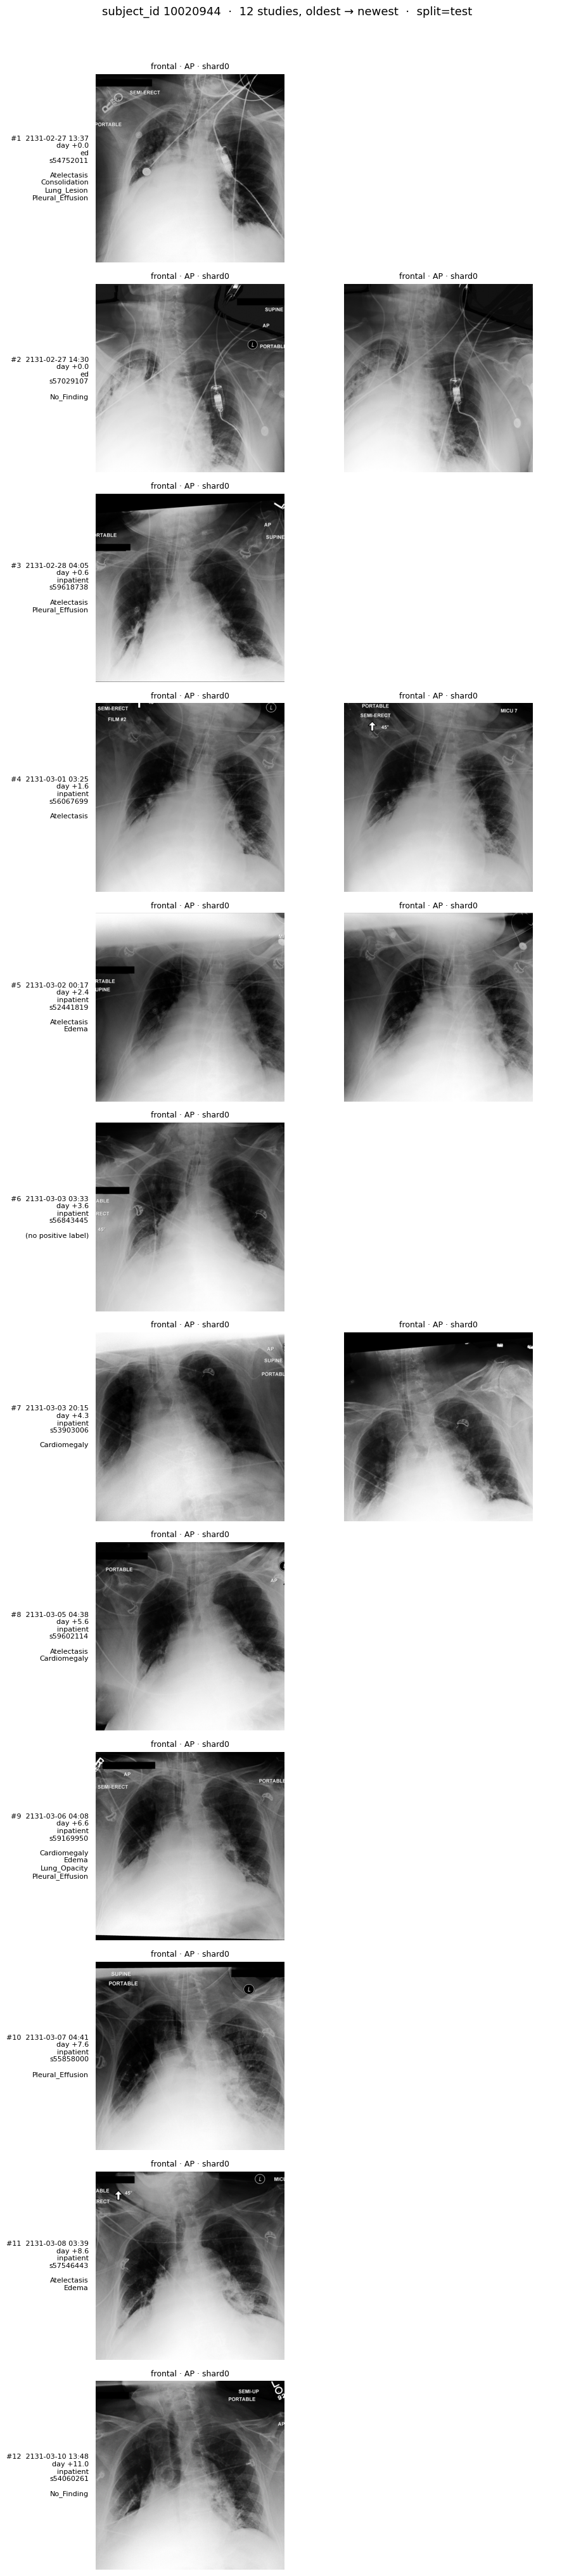

In [6]:
by_study = {k: v.head(MAX_VIEWS) for k, v in imgs.groupby('study_id')}
ncol = max((len(v) for v in by_study.values()), default=1)
nrow = len(st)

fig, axes = plt.subplots(nrow, ncol, figsize=(ROW_IN*ncol + 2.6, ROW_IN*nrow),
                         squeeze=False)
fig.suptitle(f'subject_id {SUBJ}  ·  {nrow} studies, oldest → newest  ·  '
             f'split={"/".join(sorted(st.split.unique()))}',
             fontsize=13, y=0.995)

for i, r in st.iterrows():
    rows = by_study.get(r.study_id, pd.DataFrame(columns=imgs.columns))
    for j in range(ncol):
        ax = axes[i][j]; ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_visible(False)
        if j >= len(rows):
            ax.axis('off'); continue
        g = rows.iloc[j]; im, src = pix[g.dicom_id]
        if im is None:
            ax.text(.5, .5, 'image not found', ha='center', va='center',
                    fontsize=9, color='crimson'); ax.axis('off')
        else:
            ax.imshow(im, cmap='gray')
        ax.set_title(f'{g.view_group} · {g.view_position_resolved} · {src}', fontsize=9)

    pos = ', '.join(r['pos']) if r['pos'] else '(no positive label)'
    lab = (f"#{i+1}  {r.index_time:%Y-%m-%d %H:%M}\n"
           f"day {r['day']:+.1f}\n{r.setting}\ns{r.study_id}\n\n"
           + '\n'.join(pos.split(', ')))
    axes[i][0].set_ylabel(lab, fontsize=8, rotation=0, ha='right', va='center',
                          labelpad=8)
    axes[i][0].axis('on'); axes[i][0].set_xticks([]); axes[i][0].set_yticks([])

plt.tight_layout(rect=[0, 0, 1, 0.985])
if SAVE_PNG:
    os.makedirs(SAVE_DIR, exist_ok=True)
    out = os.path.join(SAVE_DIR, f'timeline_subject_{SUBJ}.png')
    fig.savefig(out, dpi=110, bbox_inches='tight'); print('saved ->', out)
plt.show()

## C6 · Same patient, one row per study, frontal only (compact strip)

For a long history the grid above gets tall. This is the same ordering as a single
left→right strip of the frontal view, which is the one that carries most of the
signal per `03`. Skip it if the patient has few studies.

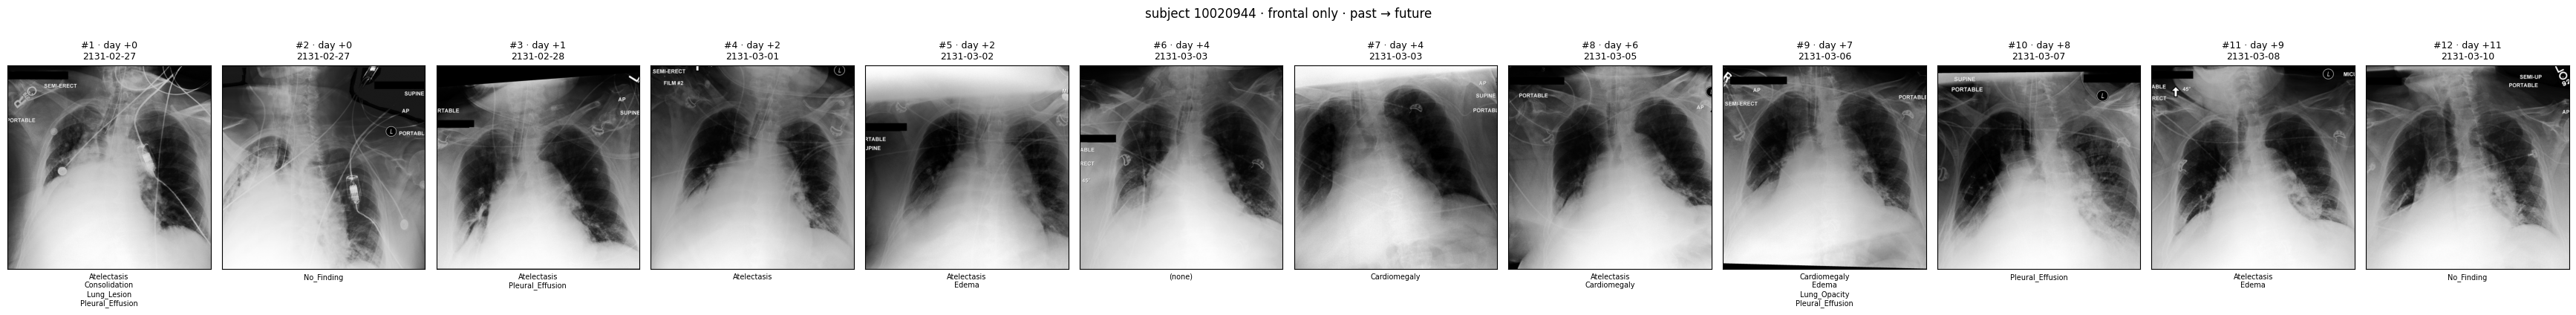

In [7]:
front = (imgs[imgs.view_group == 'frontal']
           .drop_duplicates('study_id')                      # first frontal per study
           .merge(st[['study_id','day','pos']], on='study_id')
           .sort_values('index_time', kind='stable'))
if len(front) == 0:
    print('no frontal image for this patient -- nothing to strip')
else:
    n = len(front)
    fig, axes = plt.subplots(1, n, figsize=(2.9*n, 3.9), squeeze=False)
    for k, (_, g) in enumerate(front.iterrows()):
        ax = axes[0][k]; im, src = pix[g.dicom_id]
        if im is not None: ax.imshow(im, cmap='gray')
        else: ax.text(.5, .5, 'missing', ha='center', va='center', color='crimson')
        ax.set_xticks([]); ax.set_yticks([])
        pos = ', '.join(g['pos']) if g['pos'] else '(none)'
        ax.set_title(f"#{k+1} · day {g['day']:+.0f}\n{g.index_time:%Y-%m-%d}", fontsize=9)
        ax.set_xlabel('\n'.join(pos.split(', ')), fontsize=7)
    fig.suptitle(f'subject {SUBJ} · frontal only · past → future', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

In [8]:
import os, numpy as np, pandas as pd
OUT_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out/cohort_v2'

if 'base' not in dir() or 'index_time' not in getattr(base, 'columns', []):
    base = pd.read_parquet(os.path.join(OUT_DIR, 'cohort_base.parquet'))
base['index_time'] = pd.to_datetime(base['index_time'])

META_COLS = {'study_id','subject_id','index_time','setting','cur_hadm','cur_edstay',
             'n_images','n_usable_view','n_frontal','n_lateral','n_view_ok','split'}
LABEL_COLS = [c for c in base.columns if c not in META_COLS]
NF   = next((c for c in LABEL_COLS if c.replace('_',' ').strip().lower()=='no finding'), None)
PATH = [c for c in LABEL_COLS if c != NF]
assert NF and base.study_id.is_unique
print(f'studies {len(base):,} | subjects {base.subject_id.nunique():,} | labels {len(LABEL_COLS)}')

has_h, has_e, n = base.cur_hadm.notna(), base.cur_edstay.notna(), len(base)
print('\n' + '='*62); print('A · encounter coverage of index_time'); print('='*62)
print(pd.crosstab(has_h.map({True:'hadm',False:'no hadm'}),
                  has_e.map({True:'edstay',False:'no edstay'})).to_string())
both = int((has_h & has_e).sum())
print(f'\nCXR chup trong ED nhung bi dan nhan `inpatient`: {both:,}  ({both/n:.2%} cohort)')
if both:
    print(f'   -> {both/max(int(has_e.sum()),1):.1%} cua MOI phim chup trong mot ED stay')

base['setting3'] = np.where(has_h & has_e, 'ed_admitted',
                    np.where(has_h, 'ward', np.where(has_e, 'ed_only', 'outpatient')))
prev = base.groupby('setting3')[LABEL_COLS].mean().mul(100).round(2)
prev.insert(0, 'n_studies', base.groupby('setting3').size())
order = [s for s in ['ed_only','ed_admitted','ward','outpatient'] if s in prev.index]
print('\nlabel prevalence (%) by 3-level setting'); print(prev.loc[order].to_string())

if {'ed_only','ed_admitted','ward'} <= set(prev.index):
    a,b,c = (prev.loc[s, PATH].to_numpy(float) for s in ['ed_only','ed_admitted','ward'])
    dw, de = np.abs(b-c).mean(), np.abs(b-a).mean()
    print(f'\nmean |gap| ed_admitted vs ward   : {dw:.2f} pp')
    print(f'mean |gap| ed_admitted vs ed_only: {de:.2f} pp')
    print('-> ed_admitted giong ' + ('WARD (coding hien tai on)' if dw < de else
          'ED_ONLY (precedence dang keo phim ED that su vao `inpatient`)'))


studies 211,130 | subjects 60,798 | labels 13

A · encounter coverage of index_time
cur_edstay  edstay  no edstay
cur_hadm                     
hadm          3871     106949
no hadm      77791      22519

CXR chup trong ED nhung bi dan nhan `inpatient`: 3,871  (1.83% cohort)
   -> 4.7% cua MOI phim chup trong mot ED stay

label prevalence (%) by 3-level setting
             n_studies  Atelectasis  Cardiomegaly  Consolidation  Edema  Enlarged_Cardiomediastinum  Fracture  Lung_Lesion  Lung_Opacity  No_Finding  Pleural_Effusion  Pleural_Other  Pneumonia  Pneumothorax
setting3                                                                                                                                                                                                      
ed_only          77791        14.96          9.05           3.39  12.05                        1.58      2.22         2.94         17.41       53.72             11.39           0.73      14.96          0.83
ed_admitted    

In [9]:
GAP_EDGES = [0, 1, 6, 24, 24*7, 24*365*100]
GAP_NAMES = ['<1h','1-6h','6-24h','1-7d','>7d']

d   = base.sort_values(['subject_id','index_time'], kind='stable').reset_index(drop=True)
L, P, nf = d[LABEL_COLS].to_numpy(np.int8), d[PATH].to_numpy(np.int8), d[NF].to_numpy(np.int8)
sid, sids = d.subject_id.to_numpy(), d.study_id.to_numpy()
t   = d.index_time.to_numpy('datetime64[s]').astype('int64')
same = sid[1:] == sid[:-1]

pairs = pd.DataFrame({
    'subject_id': sid[1:][same], 'prev_study': sids[:-1][same], 'study_id': sids[1:][same],
    'gap_h': (t[1:]-t[:-1])[same]/3600.0,
    'n_gain': ((L[1:]>L[:-1]).sum(1))[same], 'n_loss': ((L[1:]<L[:-1]).sum(1))[same],
    'prev_npos': P[:-1].sum(1)[same], 'cur_npos': P[1:].sum(1)[same],
    'prev_nf': nf[:-1][same], 'cur_nf': nf[1:][same]})
pairs['changed'] = (pairs.n_gain + pairs.n_loss) > 0
assert (pairs.gap_h >= -1e-9).all(), 'gap am -> sort sai'
pairs['bucket'] = pd.cut(pairs.gap_h, bins=GAP_EDGES, labels=GAP_NAMES, right=False)

g = pairs.groupby('bucket', observed=False)
tab = pd.DataFrame({'n_pairs': g.size(),
                    'pct_of_all': (g.size()/len(pairs)*100).round(2),
                    'pct_changed': (g.changed.mean()*100).round(1),
                    'mean_gain': g.n_gain.mean().round(2),
                    'mean_loss': g.n_loss.mean().round(2),
                    'median_gap_h': g.gap_h.median().round(2)})
print(f'consecutive pairs: {len(pairs):,}\n'); print(tab.to_string())

sub6 = pairs[pairs.gap_h < 6]
print(f'\npairs <6h: {len(sub6):,} ({len(sub6)/len(pairs):.1%}); '
      f'{sub6.changed.mean():.1%} bat dong >=1 nhan')
lo, hi = tab.pct_changed.iloc[0], tab.pct_changed.iloc[-1]
print(f'flip {GAP_NAMES[0]}={lo}%  vs  {GAP_NAMES[-1]}={hi}%')
print('-> ' + ('tang theo gap: tien trien that chiem uu the' if hi > lo*1.5 else
      'gan nhu PHANG qua 4 bac do lon cua thoi gian -- benh ly khong the nhu vay; '
      'day la nhieu nhan tu bao cao'))


consecutive pairs: 150,332

        n_pairs  pct_of_all  pct_changed  mean_gain  mean_loss  median_gap_h
bucket                                                                      
<1h        1062        0.71         68.0       0.69       1.04          0.69
1-6h       9204        6.12         80.4       0.95       1.16          3.46
6-24h     34278       22.80         88.7       1.28       1.23         16.11
1-7d      43414       28.88         89.4       1.36       1.25         47.73
>7d       62374       41.49         72.0       0.97       0.99       1994.77

pairs <6h: 10,266 (6.8%); 79.1% bat dong >=1 nhan
flip <1h=68.0%  vs  >7d=72.0%
-> gan nhu PHANG qua 4 bac do lon cua thoi gian -- benh ly khong the nhu vay; day la nhieu nhan tu bao cao


In [10]:
FLICKER_H = 24
collapse = pairs[(pairs.prev_npos>=1) & (pairs.cur_nf==1) & (pairs.cur_npos==0)]
print(f'collapse (pos -> No Finding sach): {len(collapse):,} pairs ({len(collapse)/len(pairs):.2%})')
print(f'   <6h: {int((collapse.gap_h<6).sum()):,}  |  <1h: {int((collapse.gap_h<1).sum()):,}')

ok3  = (sid[2:]==sid[:-2]) & (sid[1:-1]==sid[:-2])
span = (t[2:]-t[:-2])/3600.0
flick = ok3 & (P[:-2].sum(1)>=1) & ((nf[1:-1]==1)&(P[1:-1].sum(1)==0)) & (P[2:].sum(1)>=1) & (span<=FLICKER_H)
print(f'\nflicker (pos -> No Finding -> pos trong {FLICKER_H}h): {int(flick.sum()):,} triples')
print(f'   subjects anh huong: {pd.unique(sid[2:][flick]).size:,}')
if flick.sum():
    ex = pd.DataFrame({'subject_id': sid[2:][flick], 's_A': sids[:-2][flick],
                       's_B': sids[1:-1][flick], 's_C': sids[2:][flick],
                       'span_h': span[flick].round(2),
                       'A_pos': P[:-2].sum(1)[flick], 'C_pos': P[2:].sum(1)[flick]}).sort_values('span_h')
    print('\nspan ngan nhat (nem subject_id nao do vao notebook 16 de xem anh):')
    print(ex.head(12).to_string(index=False))


collapse (pos -> No Finding sach): 17,319 pairs (11.52%)
   <6h: 1,471  |  <1h: 220

flicker (pos -> No Finding -> pos trong 24h): 903 triples
   subjects anh huong: 805

span ngan nhat (nem subject_id nao do vao notebook 16 de xem anh):
 subject_id      s_A      s_B      s_C  span_h  A_pos  C_pos
   12562031 53059395 57422027 55314217    0.76      2      1
   13042648 51029438 59099072 59987820    1.14      2      2
   19454978 54844678 53886138 53961391    1.17      1      1
   13070964 57295356 57866031 55625323    1.26      2      3
   18563140 54171778 57009126 55055710    1.42      4      5
   13474359 55758240 54010661 51587495    1.43      5      2
   11015070 56086664 56298550 52957855    1.52      1      2
   15945590 59261401 53782945 50481961    1.73      4      4
   12629893 50709477 57223387 53359950    1.80      4      3
   18938959 59470896 57732668 54013946    1.97      3      1
   18693928 54930398 50374311 50580738    2.06      5      2
   15117765 58683772 57957928 

In [11]:
m6 = (pairs.gap_h < 6).to_numpy()
Lp, Lc = L[:-1][same][m6], L[1:][same][m6]
either, disag = (Lp | Lc).astype(bool), (Lp != Lc)
per = pd.DataFrame({'prevalence_%': base[LABEL_COLS].mean().mul(100).round(2),
                    'n_pairs_pos': either.sum(0),
                    'unstable_%': np.where(either.sum(0)>0,
                                  disag.sum(0)/np.maximum(either.sum(0),1)*100, np.nan).round(1)
                   }, index=LABEL_COLS).sort_values('prevalence_%')
print(f'pairs <6h dung: {int(m6.sum()):,}\n'); print(per.to_string())
print('\n(hiem nhat o tren -- dung la cac nhan duoi ma 12-15 dang danh nhau)')


pairs <6h dung: 10,266

                            prevalence_%  n_pairs_pos  unstable_%
Pleural_Other                       1.19          156        82.1
Fracture                            2.17          299        76.6
Lung_Lesion                         3.22          429        75.3
Pneumothorax                        5.11         2510        45.7
Consolidation                       6.72         1359        82.0
Enlarged_Cardiomediastinum          7.34         1685        80.5
Pneumonia                          15.29         2123        73.8
Edema                              17.97         3103        62.5
Cardiomegaly                       22.54         3536        72.6
Lung_Opacity                       24.48         4309        67.7
Atelectasis                        25.02         4509        67.3
Pleural_Effusion                   26.85         4667        54.7
No_Finding                         32.78         3292        71.1

(hiem nhat o tren -- dung la cac nhan duoi ma 12-15